# Project 12: Understanding Convolution and Pooling

**Name:** Syahrul  
**Subject:** Deep Learning

**Objective:** To understand how convolution and pooling operations extract important features from images using Python.

## Task 1: Load a Sample Image

Load and display a sample image using Python. A simple sample image is created in this notebook, so no separate upload is required.

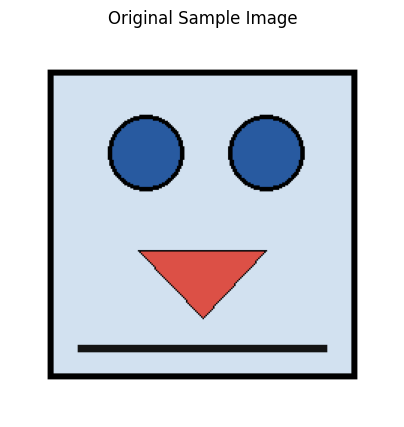

Image size: (256, 256)
Grayscale image shape: (256, 256)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from scipy.signal import convolve2d

# Create a sample image
sample = Image.new("RGB", (256, 256), "white")
draw = ImageDraw.Draw(sample)
draw.rectangle((25, 25, 230, 230), fill=(210, 225, 240), outline="black", width=4)
draw.ellipse((65, 55, 115, 105), fill=(40, 90, 160), outline="black", width=3)
draw.ellipse((145, 55, 195, 105), fill=(40, 90, 160), outline="black", width=3)
draw.polygon([(85, 145), (170, 145), (128, 190)], fill=(220, 80, 70), outline="black")
draw.line((45, 210, 210, 210), fill=(20, 20, 20), width=5)
sample.save("sample_image.png")

# Load and display the image
image = Image.open("sample_image.png").convert("RGB")
gray_image = image.convert("L")
gray_array = np.array(gray_image)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Original Sample Image")
plt.axis("off")
plt.show()

print("Image size:", image.size)
print("Grayscale image shape:", gray_array.shape)

## Task 2: Apply Convolution Filters

Apply edge detection, blur, and sharpening filters to the grayscale image to observe how each filter changes the image.

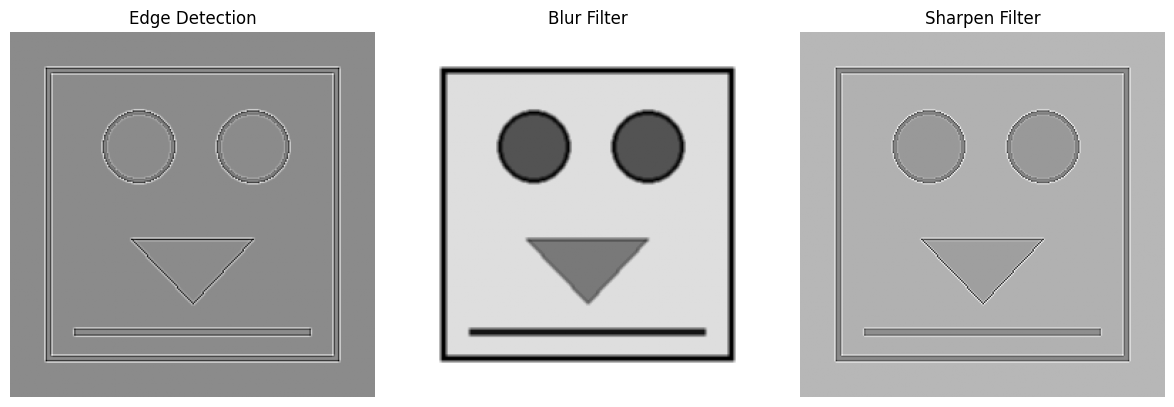

In [2]:
# Define convolution filters
edge_filter = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

blur_filter = np.ones((3, 3)) / 9

sharpen_filter = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

# Apply convolution
edge_map = convolve2d(gray_array, edge_filter, mode="same", boundary="symm")
blur_map = convolve2d(gray_array, blur_filter, mode="same", boundary="symm")
sharpen_map = convolve2d(gray_array, sharpen_filter, mode="same", boundary="symm")

# Visualize the feature maps
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(edge_map, cmap="gray")
plt.title("Edge Detection")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blur_map, cmap="gray")
plt.title("Blur Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpen_map, cmap="gray")
plt.title("Sharpen Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

## Task 3: Apply Pooling Operations

Apply 2 × 2 max pooling and average pooling. Both methods reduce the spatial size of the image from 256 × 256 to 128 × 128.

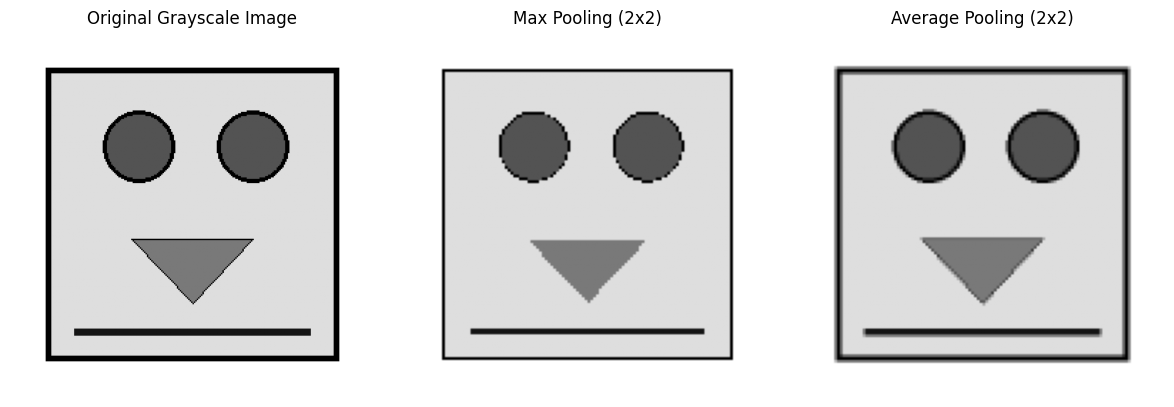

Original image shape: (256, 256)
Max pooled image shape: (128, 128)
Average pooled image shape: (128, 128)


In [3]:
# Define max pooling
def max_pooling(image_array, size=2):
    height, width = image_array.shape
    pooled = np.zeros((height // size, width // size))

    for i in range(0, height - size + 1, size):
        for j in range(0, width - size + 1, size):
            pooled[i // size, j // size] = np.max(
                image_array[i:i + size, j:j + size]
            )

    return pooled


# Define average pooling
def average_pooling(image_array, size=2):
    height, width = image_array.shape
    pooled = np.zeros((height // size, width // size))

    for i in range(0, height - size + 1, size):
        for j in range(0, width - size + 1, size):
            pooled[i // size, j // size] = np.mean(
                image_array[i:i + size, j:j + size]
            )

    return pooled


max_pooled = max_pooling(gray_array, size=2)
average_pooled = average_pooling(gray_array, size=2)

# Display and compare pooling results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray_array, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(max_pooled, cmap="gray")
plt.title("Max Pooling (2x2)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(average_pooled, cmap="gray")
plt.title("Average Pooling (2x2)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Original image shape:", gray_array.shape)
print("Max pooled image shape:", max_pooled.shape)
print("Average pooled image shape:", average_pooled.shape)

## Observations

- The edge detection filter highlights boundaries and sharp changes in brightness.
- The blur filter smooths the image.
- The sharpening filter emphasizes edges and details.
- Max pooling selects the largest value from each 2 × 2 region.
- Average pooling calculates the mean value from each 2 × 2 region.
- Both pooling methods reduce the image dimensions.

## Result

Convolution filters produced different feature maps from the sample image. Max pooling and average pooling reduced the image dimensions while summarizing local image information.

## Conclusion

Convolution helps extract visual features, while pooling reduces spatial dimensions and summarizes local regions. These operations are important components of Convolutional Neural Networks (CNNs).